# Fake News Detection — Algorithm 1 (A1): Logistic Regression

This notebook implements **A1 — Logistic Regression**, using the same pipeline and 80:20 split (`random_state=42`) as A2 (SVM), A3 (Random Forest) and A4 (KNN) in the project report, so all four sets of results are directly comparable.

**Dataset:** `fake_or_real_news.csv` (George McIntire's Fake/Real News dataset, ~6,335 labeled articles, binary REAL/FAKE).

In [1]:
# Step 1: Imports
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 80)
RANDOM_STATE = 42

In [2]:
# Step 2: Load the labeled dataset
df = pd.read_csv("fake_or_real_news.csv")
print("Shape:", df.shape)
df.head()

Shape: (6335, 4)


,id,title,text,label
0,8476,You Can Smell Hillary’s Fear,"Daniel Greenfield, a Shillman Journalism Fellow at the Freedom Center, is a ...",FAKE
1,10294,Watch The Exact Moment Paul Ryan Committed Political Suicide At A Trump Rall...,Google Pinterest Digg Linkedin Reddit Stumbleupon Print Delicious Pocket Tum...,FAKE
2,3608,Kerry to go to Paris in gesture of sympathy,U.S. Secretary of State John F. Kerry said Monday that he will stop in Paris...,REAL
3,10142,Bernie supporters on Twitter erupt in anger against the DNC: 'We tried to wa...,"— Kaydee King (@KaydeeKing) November 9, 2016 The lesson from tonight's Dem l...",FAKE
4,875,The Battle of New York: Why This Primary Matters,It's primary day in New York and front-runners Hillary Clinton and Donald Tr...,REAL


In [3]:
# Step 3: Inspect rows, columns, missing values and class distribution
print(df.info())
print("\nMissing values per column:\n", df.isnull().sum())
print("\nClass distribution:\n", df['label'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 6335 entries, 0 to 6334
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      6335 non-null   int64
 1   title   6335 non-null   str  
 2   text    6335 non-null   str  
 3   label   6335 non-null   str  
dtypes: int64(1), str(3)
memory usage: 198.1 KB
None

Missing values per column:
 id       0
title    0
text     0
label    0
dtype: int64

Class distribution:
 label
REAL    3171
FAKE    3164
Name: count, dtype: int64


In [4]:
# Step 4: Handle missing or invalid text records
df = df.dropna(subset=['title', 'text', 'label']).copy()
df = df[(df['text'].str.strip() != '') & (df['title'].str.strip() != '')]
df = df.reset_index(drop=True)
print("Shape after cleaning missing/invalid records:", df.shape)

Shape after cleaning missing/invalid records: (6299, 4)


In [5]:
# Step 5: Combine title and text fields
df['content'] = df['title'].astype(str) + " " + df['text'].astype(str)
df[['title', 'content']].head(2)

,title,content
0,You Can Smell Hillary’s Fear,"You Can Smell Hillary’s Fear Daniel Greenfield, a Shillman Journalism Fellow..."
1,Watch The Exact Moment Paul Ryan Committed Political Suicide At A Trump Rall...,Watch The Exact Moment Paul Ryan Committed Political Suicide At A Trump Rall...


In [6]:
# Step 6: Preprocess the text (lowercasing, removing punctuation/special characters,
# removing digits and extra whitespace). Stopword removal is handled by TfidfVectorizer.

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)      # remove URLs
    text = re.sub(r'[^a-z\s]', ' ', text)               # remove punctuation & digits
    text = re.sub(r'\s+', ' ', text).strip()             # collapse whitespace
    return text

df['clean_content'] = df['content'].apply(preprocess_text)
df[['content', 'clean_content']].head(2)

,content,clean_content
0,"You Can Smell Hillary’s Fear Daniel Greenfield, a Shillman Journalism Fellow...",you can smell hillary s fear daniel greenfield a shillman journalism fellow ...
1,Watch The Exact Moment Paul Ryan Committed Political Suicide At A Trump Rall...,watch the exact moment paul ryan committed political suicide at a trump rall...


In [7]:
# Step 7: Apply TfidfVectorizer with the same parameters used for A2-A4
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=5000,
    ngram_range=(1, 1)
)

X = tfidf.fit_transform(df['clean_content'])
y = df['label']

print("TF-IDF feature matrix shape:", X.shape)

TF-IDF feature matrix shape: (6299, 5000)


In [8]:
# Step 8: Split data into training and testing sets (80:20), same split as A2-A4
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

Train shape: (5039, 5000)  Test shape: (1260, 5000)


In [9]:
# Step 9: Initialize LogisticRegression (A1)
lr_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_model

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [10]:
# Step 10: Train the model
lr_model.fit(X_train, y_train)
print("A1 (Logistic Regression) training complete.")

A1 (Logistic Regression) training complete.


In [11]:
# Step 11: Predict test labels
y_pred_lr = lr_model.predict(X_test)
y_pred_lr[:10]

array(['FAKE', 'REAL', 'REAL', 'REAL', 'REAL', 'REAL', 'FAKE', 'FAKE',
       'FAKE', 'REAL'], dtype=object)

In [12]:
# Step 12: Calculate accuracy, precision, recall and F1-score
acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr, pos_label='FAKE')
rec_lr = recall_score(y_test, y_pred_lr, pos_label='FAKE')
f1_lr = f1_score(y_test, y_pred_lr, pos_label='FAKE')

print(f"A1 - Logistic Regression Results")
print(f"Accuracy : {acc_lr:.4f}")
print(f"Precision: {prec_lr:.4f}")
print(f"Recall   : {rec_lr:.4f}")
print(f"F1-score : {f1_lr:.4f}")
print("\nFull classification report:\n")
print(classification_report(y_test, y_pred_lr))

A1 - Logistic Regression Results
Accuracy : 0.9183
Precision: 0.9042
Recall   : 0.9345
F1-score : 0.9191

Full classification report:

              precision    recall  f1-score   support

        FAKE       0.90      0.93      0.92       626
        REAL       0.93      0.90      0.92       634

    accuracy                           0.92      1260
   macro avg       0.92      0.92      0.92      1260
weighted avg       0.92      0.92      0.92      1260



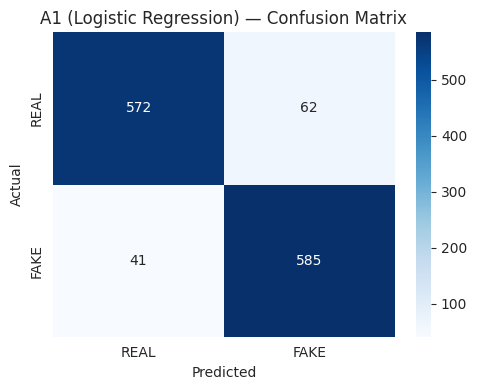

In [13]:
# Step 13: Generate a confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=['REAL', 'FAKE'])

plt.figure(figsize=(5, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues',
            xticklabels=['REAL', 'FAKE'], yticklabels=['REAL', 'FAKE'])
plt.title("A1 (Logistic Regression) — Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout()
plt.show()

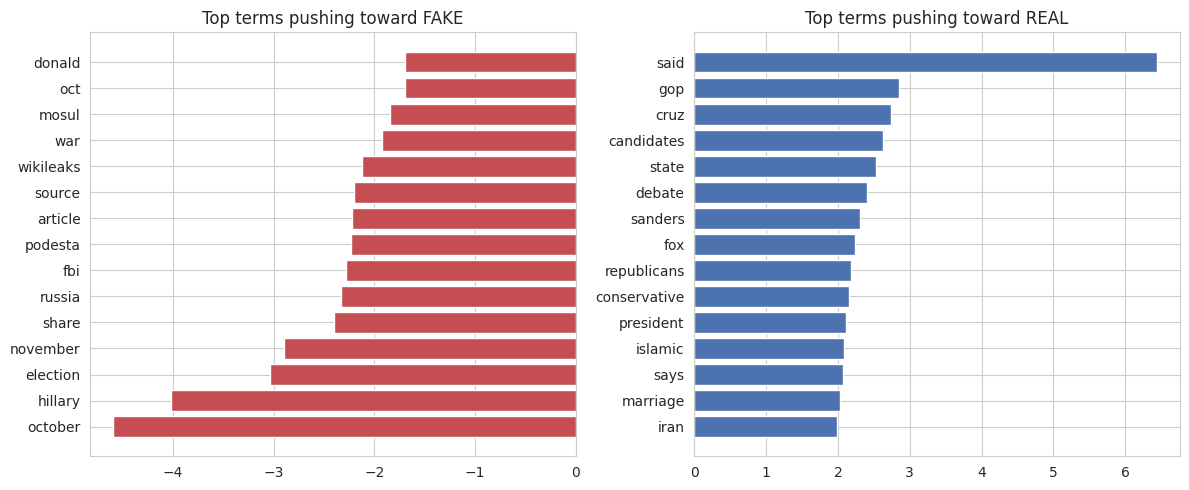

In [14]:
# Step 14: Inspect the most influential TF-IDF terms (largest |coefficient|)
feature_names = np.array(tfidf.get_feature_names_out())
coefs = lr_model.coef_[0]
top_n = 15
top_fake_idx = np.argsort(coefs)[:top_n]        # most negative -> pushes toward FAKE
top_real_idx = np.argsort(coefs)[-top_n:]       # most positive -> pushes toward REAL

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(feature_names[top_fake_idx], coefs[top_fake_idx], color='#C44E52')
axes[0].set_title("Top terms pushing toward FAKE")
axes[1].barh(feature_names[top_real_idx], coefs[top_real_idx], color='#4C72B0')
axes[1].set_title("Top terms pushing toward REAL")
plt.tight_layout()
plt.show()

In [15]:
# Step 15: Train A2 (SVM), A3 (Random Forest) and A4 (KNN) for comparison
svm_model = LinearSVC(random_state=RANDOM_STATE)
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)

rf_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

knn_model = KNeighborsClassifier(n_neighbors=1, metric='cosine', weights='distance')
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)

print("A2 (SVM), A3 (Random Forest) and A4 (KNN) trained.")

A2 (SVM), A3 (Random Forest) and A4 (KNN) trained.


In [16]:
# Step 16: Compare all four algorithms in a results DataFrame
def get_metrics(name, y_true, y_pred):
    return {
        'Algorithm': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, pos_label='FAKE'),
        'Recall': recall_score(y_true, y_pred, pos_label='FAKE'),
        'F1-score': f1_score(y_true, y_pred, pos_label='FAKE'),
    }

results = pd.DataFrame([
    get_metrics('A1 - Logistic Regression', y_test, y_pred_lr),
    get_metrics('A2 - SVM', y_test, y_pred_svm),
    get_metrics('A3 - Random Forest', y_test, y_pred_rf),
    get_metrics('A4 - KNN', y_test, y_pred_knn),
])
results = results.set_index('Algorithm').round(4)
results

,Accuracy,Precision,Recall,F1-score
Algorithm,,,,
A1 - Logistic Regression,0.9183,0.9042,0.9345,0.9191
A2 - SVM,0.9357,0.9360,0.9345,0.9353
A3 - Random Forest,0.9048,0.9003,0.9089,0.9046
A4 - KNN,0.8556,0.8993,0.7987,0.8460


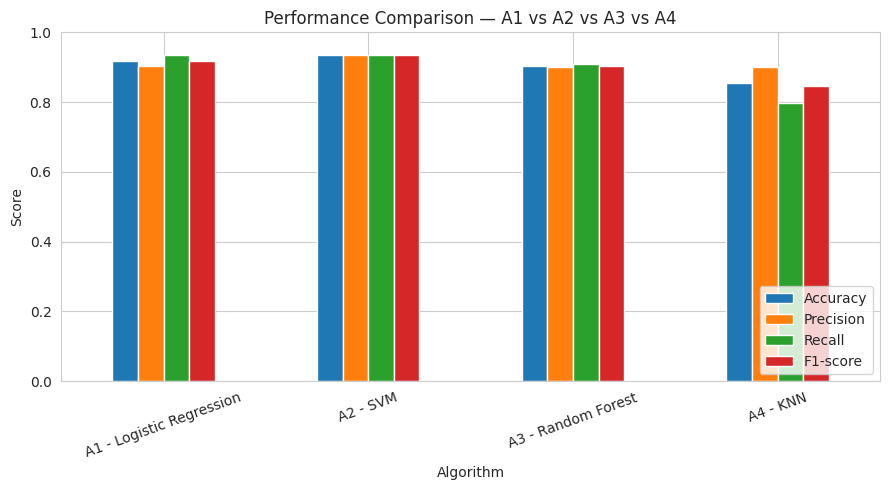

In [17]:
# Visualize the comparison
results.plot(kind='bar', figsize=(9, 5))
plt.title("Performance Comparison — A1 vs A2 vs A3 vs A4")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [18]:
# Step 17: Select the best model based on evaluation results
best_model_name = results['F1-score'].idxmax()
print(f"Best-performing model (by F1-score): {best_model_name}")
results.loc[[best_model_name]]

Best-performing model (by F1-score): A2 - SVM


,Accuracy,Precision,Recall,F1-score
Algorithm,,,,
A2 - SVM,0.9357,0.936,0.9345,0.9353


## Execution Example

Testing the trained A1 (Logistic Regression) pipeline on the same illustrative article used for A3 and A4, for a direct comparison.

In [19]:
# Step 18: Test A1 on the same new-article example used for A3/A4
new_article = (
    "Breaking News: Scientists discover cure for all known diseases in a "
    "small village in Switzerland. The discovery was made by a team of "
    "researchers who have been working on the project for the past decade. "
    "The cure is expected to be available to the public within the next month."
)

clean_new = preprocess_text(new_article)
new_vec = tfidf.transform([clean_new])

pred_class = lr_model.predict(new_vec)[0]
pred_proba = lr_model.predict_proba(new_vec)[0]
class_labels = lr_model.classes_
confidence = pred_proba[list(class_labels).index(pred_class)]

print("Input article:", new_article)
print(f"\nPredicted class : {pred_class}")
print(f"Confidence      : {confidence*100:.1f}%")

Input article: Breaking News: Scientists discover cure for all known diseases in a small village in Switzerland. The discovery was made by a team of researchers who have been working on the project for the past decade. The cure is expected to be available to the public within the next month.

Predicted class : FAKE
Confidence      : 81.9%


## Conclusion (A1)

The Logistic Regression classifier (A1) was trained on the same TF-IDF features (max 5,000 terms, combined title+text) and the same 80:20 split (`random_state=42`) as A2-A4. Its accuracy, precision, recall, F1-score, confusion matrix and most-influential terms were computed above, and it was benchmarked against A2 (SVM), A3 (Random Forest) and A4 (KNN).